# 03 — Train GPT from Scratch

This notebook imports the decoder implementation from `src/gpt_model.py`, loads the BPE tokenizer and processed data written by Notebook 02, and trains from random initialization.

Run from the project root. For Kaggle, copy the project to `/kaggle/working/` first because `/kaggle/input/` is read-only.

In [2]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("train.jsonl"):
    print(p)

/kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6/data/processed/train.jsonl


In [3]:
from pathlib import Path

PREPROCESS_DIR = Path(
    "/kaggle/input/notebooks/naveedahmad6511/"
    "notebook1c8b40c6f6"
)

for name in [
    "data/processed/train.jsonl",
    "data/processed/validation.jsonl",
    "data/processed/test.jsonl",
    "artifacts/tokenizer/tokenizer.json"
]:
    path = PREPROCESS_DIR / name
    print(("FOUND " if path.exists() else "MISSING "), path)

FOUND  /kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6/data/processed/train.jsonl
FOUND  /kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6/data/processed/validation.jsonl
FOUND  /kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6/data/processed/test.jsonl
FOUND  /kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6/artifacts/tokenizer/tokenizer.json


In [4]:
from pathlib import Path
from tokenizers import Tokenizer

# Notebook 02 outputs
PREPROCESS_DIR = Path(
    "/kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6"
)

TOKENIZER_PATH = PREPROCESS_DIR / "artifacts/tokenizer/tokenizer.json"
TRAIN_PATH = PREPROCESS_DIR / "data/processed/train.jsonl"
VAL_PATH = PREPROCESS_DIR / "data/processed/validation.jsonl"
TEST_PATH = PREPROCESS_DIR / "data/processed/test.jsonl"

# Verify files
required_files = [
    TOKENIZER_PATH,
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH
]

for path in required_files:
    assert path.exists(), f"Missing file: {path}"
    print("FOUND:", path.name)

# Load tokenizer
tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))

print("\nTokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.get_vocab_size())
print("Special tokens:", {
    token: tokenizer.token_to_id(token)
    for token in ["<pad>", "<bos>", "<eos>", "<unk>", "<dialogue>", "<summary>"]
})

FOUND: tokenizer.json
FOUND: train.jsonl
FOUND: validation.jsonl
FOUND: test.jsonl

Tokenizer loaded successfully!
Vocabulary size: 8192
Special tokens: {'<pad>': 0, '<bos>': 1, '<eos>': 2, '<unk>': 3, '<dialogue>': 4, '<summary>': 5}


In [5]:
import json

with open(TRAIN_PATH, "r", encoding="utf-8") as f:
    first_example = json.loads(next(f))

print("Available keys:", first_example.keys())

for key, value in first_example.items():
    if isinstance(value, list):
        print(f"{key}: length={len(value)}, first 10={value[:10]}")
    else:
        print(f"{key}: {str(value)[:200]}")

Available keys: dict_keys(['input_ids', 'prompt_length', 'reference', 'dialogue'])
input_ids: length=54, first 10=[1, 41, 1152, 1050, 630, 31, 204, 1610, 31, 273]
prompt_length: 43
reference: Amanda baked cookies and will bring Jerry some tomorrow.
dialogue: Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)


In [6]:
ids = first_example["input_ids"]
prompt_length = first_example["prompt_length"]

print("Total tokens:", len(ids))
print("Prompt length:", prompt_length)
print("Summary marker ID:", tokenizer.token_to_id("<summary>"))
print("Summary marker position:", ids.index(tokenizer.token_to_id("<summary>")))

print("\nInput length:", len(ids[:-1]))
print("Target length:", len(ids[1:]))
print("First summary target position:", prompt_length)
print("Number of summary targets:", len(ids) - prompt_length)

Total tokens: 54
Prompt length: 43
Summary marker ID: 5
Summary marker position: 42

Input length: 53
Target length: 53
First summary target position: 43
Number of summary targets: 11


In [7]:
import tensorflow as tf

def create_loss_mask(prompt_lengths, sequence_length):
    """
    prompt_lengths: [batch_size]
    sequence_length: length of shifted targets
    """
    positions = tf.range(sequence_length)[tf.newaxis, :]

    # First summary target is at prompt_length - 1
    mask = positions >= (prompt_lengths[:, tf.newaxis] - 1)

    return tf.cast(mask, tf.float32)

In [8]:
import sys
import json
from pathlib import Path

# Automatically locate the project
matches = [
    p for p in Path("/kaggle/input").rglob("config.json")
    if p.parent.name == "configs"
    and (p.parent.parent / "src" / "gpt_model.py").exists()
]

if not matches:
    raise FileNotFoundError("GPT project directory not found.")

ROOT = matches[0].parent.parent

# Load configuration
with open(ROOT / "configs" / "config.json", "r") as f:
    CFG = json.load(f)

# Import GPT architecture
sys.path.insert(0, str(ROOT / "src"))

from gpt_model import GPTConfig, GPTSummarizer

print("Project root:", ROOT)
print("GPT model imported successfully!")

Project root: /kaggle/input/datasets/naveedahmad6511/gpt-base-text-summerizer/SAMSum-GPT-TensorFlow
GPT model imported successfully!


In [9]:
import json
import tensorflow as tf
from pathlib import Path

# Paths to Notebook 02 outputs
PREPROCESS_DIR = Path(
    "/kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6"
)

# Configuration
MAX_LEN = CFG["sequence"]["max_length"]
BATCH_SIZE = CFG["training"]["batch_size"]
PAD_ID = tokenizer.token_to_id("<pad>")
SEED = CFG["seed"]

# Load JSONL files
def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))
    return rows

train_rows = read_jsonl(PREPROCESS_DIR / "data/processed/train.jsonl")
val_rows = read_jsonl(PREPROCESS_DIR / "data/processed/validation.jsonl")
test_rows = read_jsonl(PREPROCESS_DIR / "data/processed/test.jsonl")

print("Training examples:", len(train_rows))
print("Validation examples:", len(val_rows))
print("Test examples:", len(test_rows))


# Prepare next-token prediction examples
def make_arrays(rows):
    x_list, y_list = [], []

    for row in rows:
        ids = row["input_ids"][:MAX_LEN]

        if len(ids) < 2:
            continue

        x = ids[:-1]
        y = ids[1:]

        prompt_len = row["prompt_length"]

        # Ignore dialogue and prompt targets.
        # First summary target is at prompt_len - 1.
        y[:prompt_len - 1] = [-100] * min(prompt_len - 1, len(y))

        x_list.append(x)
        y_list.append(y)

    return x_list, y_list


# Build TensorFlow datasets
def make_dataset(rows, training=False):
    xs, ys = make_arrays(rows)

    ds = tf.data.Dataset.from_generator(
        lambda: iter(zip(xs, ys)),
        output_signature=(
            tf.TensorSpec(shape=(None,), dtype=tf.int32),
            tf.TensorSpec(shape=(None,), dtype=tf.int32)
        )
    )

    if training:
        ds = ds.shuffle(
            buffer_size=2048,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.padded_batch(
        BATCH_SIZE,
        padded_shapes=([MAX_LEN - 1], [MAX_LEN - 1]),
        padding_values=(
            tf.constant(PAD_ID, tf.int32),
            tf.constant(-100, tf.int32)
        ),
        drop_remainder=training
    )

    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_rows, training=True)
val_ds = make_dataset(val_rows)
test_ds = make_dataset(test_rows)
import math

train_batches = (
    len(train_rows) // BATCH_SIZE
)

val_batches = math.ceil(len(val_rows) / BATCH_SIZE)
test_batches = math.ceil(len(test_rows) / BATCH_SIZE)

print("\nDataset preparation complete.")
print("Training examples:", len(train_rows))
print("Validation examples:", len(val_rows))
print("Test examples:", len(test_rows))

print("\nTraining batches:", train_batches)
print("Validation batches:", val_batches)
print("Test batches:", test_batches)

Training examples: 14732
Validation examples: 818
Test examples: 819

Dataset preparation complete.
Training examples: 14732
Validation examples: 818
Test examples: 819

Training batches: 1841
Validation batches: 103
Test batches: 103


In [10]:
# Model configuration
VOCAB_SIZE = tokenizer.get_vocab_size()
PAD_ID = tokenizer.token_to_id("<pad>")

model_cfg = dict(CFG["model"])
model_cfg["vocab_size"] = VOCAB_SIZE
model_cfg["pad_id"] = PAD_ID

model_config = GPTConfig(**model_cfg)

# Initialize GPT model
model = GPTSummarizer(model_config)

# Build model variables
dummy_input = tf.constant([[1, 2, PAD_ID]], dtype=tf.int32)
_ = model(dummy_input)

model.summary()

Model: "gpt_summarizer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (1, 3, 512)            │     4,194,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (3, 512)               │       262,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_4             │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_5             │ ?                      │     3,152,384 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_12          │ (1, 3, 512)            │         1,024 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (1, 3, 8192)           │     4,194,304 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,566,080 (105.16 MB)

 Trainable params: 27,566,080 (105.16 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
strategy = tf.distribute.MirroredStrategy(
    devices=["/GPU:0", "/GPU:1"]
)

with strategy.scope():

    model = GPTSummarizer(model_config)

    # Build model variables first
    dummy_input = tf.constant([[1, 2, PAD_ID]], dtype=tf.int32)
    _ = model(dummy_input)

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=CFG["training"]["learning_rate"],
        weight_decay=CFG["training"]["weight_decay"],
        beta_1=0.9,
        beta_2=0.95,
        epsilon=1e-8,
        global_clipnorm=CFG["training"]["max_grad_norm"]
    )

    # IMPORTANT: Create optimizer slots before distributed training
    optimizer.build(model.trainable_variables)

print("GPUs:", strategy.num_replicas_in_sync)
print("Model parameters:", model.count_params())
print("Optimizer variables:", len(optimizer.variables))

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
GPUs: 2
Model parameters: 27566080
Optimizer variables: 156


In [12]:
BATCH_SIZE = 32

train_ds = make_dataset(train_rows, training=True)
val_ds = make_dataset(val_rows, training=True)

dist_train_ds = strategy.experimental_distribute_dataset(train_ds)
dist_val_ds = strategy.experimental_distribute_dataset(val_ds)

In [13]:
train_ds = make_dataset(train_rows, training=True)

val_ds = make_dataset(val_rows, training=True)

dist_train_ds = strategy.experimental_distribute_dataset(train_ds)
dist_val_ds = strategy.experimental_distribute_dataset(val_ds)

print("Training batches:", len(train_rows) // BATCH_SIZE)
print("Validation batches:", len(val_rows) // BATCH_SIZE)

Training batches: 460
Validation batches: 25


In [14]:
learning_rate = 0.0002

In [15]:

# 
dist_train_ds = strategy.experimental_distribute_dataset(train_ds)

# Rebuild validation dataset with drop_remainder=True
val_ds_distributed = make_dataset(val_rows, training=True)

dist_val_ds = strategy.experimental_distribute_dataset(
    val_ds_distributed
)

print("Global batch size:", BATCH_SIZE)
print("Per-GPU batch size:", BATCH_SIZE // 2)
print("Training batches:", train_batches)
print("Validation batches:", len(val_rows) // BATCH_SIZE)


Global batch size: 32
Per-GPU batch size: 16
Training batches: 1841
Validation batches: 25


In [16]:
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)


def replica_train_step(input_ids, labels):

    with tf.GradientTape() as tape:

        logits = model(input_ids, training=True)

        valid_mask = tf.not_equal(labels, -100)
        safe_labels = tf.where(valid_mask, labels, 0)

        token_losses = loss_object(safe_labels, logits)

        mask = tf.cast(valid_mask, token_losses.dtype)

        local_loss_sum = tf.reduce_sum(token_losses * mask)
        local_token_count = tf.reduce_sum(mask)

        context = tf.distribute.get_replica_context()

        global_token_count = context.all_reduce(
            tf.distribute.ReduceOp.SUM,
            local_token_count
        )

        loss = local_loss_sum / tf.maximum(global_token_count, 1.0)

    gradients = tape.gradient(loss, model.trainable_variables)

    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    return local_loss_sum, local_token_count


@tf.function
def distributed_train_step(batch):

    per_loss, per_tokens = strategy.run(
        replica_train_step,
        args=batch
    )

    total_loss = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_loss,
        axis=None
    )

    total_tokens = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_tokens,
        axis=None
    )

    return total_loss, total_tokens

In [17]:
# Fetch only one distributed batch
test_batch = next(iter(dist_train_ds))

loss, tokens = distributed_train_step(test_batch)

print("Test training step successful!")
print("Loss:", float(loss.numpy() / tokens.numpy()))
print("Valid tokens:", int(tokens.numpy()))

INFO:tensorflow:Collective all_reduce tensors: 1 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce tensors: 77 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Test training step successful!
Loss: 9.084890365600586
Valid tokens: 846


In [20]:
def replica_val_step(input_ids, labels):

    logits = model(input_ids, training=False)

    valid_mask = tf.not_equal(labels, -100)
    safe_labels = tf.where(valid_mask, labels, 0)

    token_losses = loss_object(safe_labels, logits)

    mask = tf.cast(valid_mask, token_losses.dtype)

    loss_sum = tf.reduce_sum(token_losses * mask)
    token_count = tf.reduce_sum(mask)

    return loss_sum, token_count


@tf.function
def distributed_val_step(batch):

    per_loss, per_tokens = strategy.run(
        replica_val_step,
        args=batch
    )

    total_loss = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_loss,
        axis=None
    )

    total_tokens = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_tokens,
        axis=None
    )

    return total_loss, total_tokens

In [21]:
test_val_batch = next(iter(dist_val_ds))

val_loss, val_tokens = distributed_val_step(test_val_batch)

print("Validation step successful!")
print("Validation loss:", float(val_loss.numpy() / val_tokens.numpy()))
print("Valid tokens:", int(val_tokens.numpy()))

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Validation step successful!
Validation loss: 5.286204814910889
Valid tokens: 944


In [22]:
import time 
OUTPUT_DIR = Path("/kaggle/working/SAMSum-GPT-TensorFlow")

ckpt_dir = OUTPUT_DIR / "artifacts" / "checkpoints"
results_dir = OUTPUT_DIR / "results"

ckpt_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

best_path = ckpt_dir / "best.weights.h5"

history = {
    "train_loss": [],
    "val_loss": []
}

best_val = float("inf")
wait = 0

EPOCHS = CFG["training"]["epochs"]
PATIENCE = CFG["training"]["patience"]


for epoch in range(EPOCHS):

    start = time.time()

    train_loss_sum = 0.0
    train_token_count = 0.0

    val_loss_sum = 0.0
    val_token_count = 0.0

    # Training
    for batch in dist_train_ds:

        batch_loss, batch_tokens = distributed_train_step(batch)

        train_loss_sum += float(batch_loss.numpy())
        train_token_count += float(batch_tokens.numpy())

    # Validation
    for batch in dist_val_ds:

        batch_loss, batch_tokens = distributed_val_step(batch)

        val_loss_sum += float(batch_loss.numpy())
        val_token_count += float(batch_tokens.numpy())

    train_loss = train_loss_sum / max(train_token_count, 1.0)
    val_loss = val_loss_sum / max(val_token_count, 1.0)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    elapsed = (time.time() - start) / 60

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.2f} min"
    )

    if val_loss < best_val:

        best_val = val_loss
        wait = 0

        model.save_weights(best_path)

        with open(ckpt_dir / "model_config.json", "w") as f:
            json.dump(model_config.to_dict(), f, indent=2)

        print("Best checkpoint saved.")

    else:

        wait += 1
        print(f"No improvement: {wait}/{PATIENCE}")

        if wait >= PATIENCE:
            print("Early stopping triggered.")
            break


# Restore best model
model.load_weights(best_path)

with open(results_dir / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("\nTraining completed.")
print("Best validation loss:", best_val)
print("Saved model:", best_path)


Epoch 1/20 | Train Loss: 5.1501 | Val Loss: 5.0431 | Time: 5.50 min
Best checkpoint saved.
Epoch 2/20 | Train Loss: 4.8964 | Val Loss: 4.8607 | Time: 5.47 min
Best checkpoint saved.
Epoch 3/20 | Train Loss: 4.6842 | Val Loss: 4.7271 | Time: 5.47 min
Best checkpoint saved.
Epoch 4/20 | Train Loss: 4.4838 | Val Loss: 4.5989 | Time: 5.48 min
Best checkpoint saved.
Epoch 5/20 | Train Loss: 4.2970 | Val Loss: 4.4907 | Time: 5.48 min
Best checkpoint saved.
Epoch 6/20 | Train Loss: 4.1058 | Val Loss: 4.4338 | Time: 5.48 min
Best checkpoint saved.
Epoch 7/20 | Train Loss: 3.9060 | Val Loss: 4.3318 | Time: 5.48 min
Best checkpoint saved.
Epoch 8/20 | Train Loss: 3.6963 | Val Loss: 4.2922 | Time: 5.48 min
Best checkpoint saved.
Epoch 9/20 | Train Loss: 3.4842 | Val Loss: 4.2468 | Time: 5.48 min
Best checkpoint saved.
Epoch 10/20 | Train Loss: 3.2714 | Val Loss: 4.2392 | Time: 5.48 min
Best checkpoint saved.
Epoch 11/20 | Train Loss: 3.0572 | Val Loss: 4.2628 | Time: 5.49 min
No improvement: 1/3


Epochs completed: 13
Best epoch: 10
Best training loss: 3.2714
Best validation loss: 4.2392
Final training loss: 2.6355
Final validation loss: 4.3381


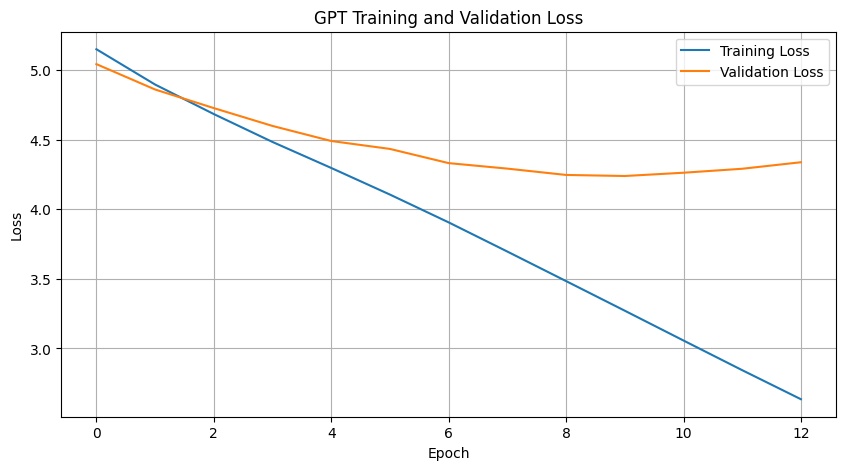

In [23]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

OUTPUT_DIR = Path("/kaggle/working/SAMSum-GPT-TensorFlow")

history_path = OUTPUT_DIR / "results" / "training_history.json"

# Load history if needed
if "history" not in globals():
    with open(history_path, "r") as f:
        history = json.load(f)

train_losses = history["train_loss"]
val_losses = history["val_loss"]

best_epoch = int(np.argmin(val_losses)) + 1

print("Epochs completed:", len(train_losses))
print("Best epoch:", best_epoch)
print("Best training loss:", f"{train_losses[best_epoch-1]:.4f}")
print("Best validation loss:", f"{val_losses[best_epoch-1]:.4f}")
print("Final training loss:", f"{train_losses[-1]:.4f}")
print("Final validation loss:", f"{val_losses[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GPT Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Restore best checkpoint
best_path = (
    OUTPUT_DIR / "artifacts" / "checkpoints" / "best.weights.h5"
)

model.load_weights(best_path)

# Create test dataset with global batch size 32
test_ds = make_dataset(test_rows, training=False)

dist_test_ds = strategy.experimental_distribute_dataset(test_ds)

test_loss_sum = 0.0
test_token_count = 0.0

for batch in dist_test_ds:

    batch_loss, batch_tokens = distributed_val_step(batch)

    test_loss_sum += float(batch_loss.numpy())
    test_token_count += float(batch_tokens.numpy())

test_loss = test_loss_sum / max(test_token_count, 1.0)

print("Test Loss:", f"{test_loss:.4f}")
print("Test Perplexity:", f"{np.exp(test_loss):.4f}")

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Test Loss: 4.2112
Test Perplexity: 67.4398


In [25]:
best_path = (
    OUTPUT_DIR / "artifacts" / "checkpoints" / "best.weights.h5"
)

model.load_weights(best_path)

print("Best model loaded successfully.")

Best model loaded successfully.


In [26]:
import tensorflow as tf
import numpy as np

BOS_ID = tokenizer.token_to_id("<bos>")
EOS_ID = tokenizer.token_to_id("<eos>")
PAD_ID = tokenizer.token_to_id("<pad>")

MAX_LEN = CFG["sequence"]["max_length"]


def generate_summary(row, max_new_tokens=100):

    # prompt_length includes the <summary> marker
    prompt_ids = row["input_ids"][:row["prompt_length"]]

    input_ids = tf.constant([prompt_ids], dtype=tf.int32)

    generated_ids = []

    for _ in range(max_new_tokens):

        logits = model(input_ids, training=False)

        # Predictions for the next token
        next_token_logits = logits[:, -1, :]

        # Greedy decoding
        next_token = tf.argmax(
            next_token_logits,
            axis=-1,
            output_type=tf.int32
        )

        next_token_id = int(next_token[0].numpy())

        if next_token_id == EOS_ID:
            break

        generated_ids.append(next_token_id)

        next_token = tf.reshape(next_token, [1, 1])

        input_ids = tf.concat(
            [input_ids, next_token],
            axis=1
        )

        # Respect model's positional embedding limit
        if input_ids.shape[1] >= MAX_LEN:
            break

    generated_summary = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    return generated_summary.strip()

In [27]:
import random

random.seed(42)

# Select 5 examples from the test set
sample_indices = random.sample(
    range(len(test_rows)),
    5
)

for i, idx in enumerate(sample_indices, 1):

    row = test_rows[idx]

    prediction = generate_summary(row)

    print("=" * 80)
    print(f"EXAMPLE {i}")
    print("=" * 80)

    print("\nDIALOGUE:\n")
    print(row["dialogue"])

    print("\nREFERENCE SUMMARY:\n")
    print(row["reference"])

    print("\nGPT GENERATED SUMMARY:\n")
    print(prediction)

    print("\n")

EXAMPLE 1

DIALOGUE:

Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season he's more mature
Clay: Yeah, Jose has his trust in him
Richie: everyone does
Clay: yeah, he really deserved to score after his first 60 minutes
Richie: reward
Clay: yeah man
Richie: cool then 
Clay: cool

REFERENCE SUMMARY:

Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player. 

GPT GENERATED SUMMARY:

Codo hasn't seen the last episode yet. He is going to the last night.


EXAMPLE 2

DIALOGUE:

Lincoln: Heeyyy ;* whats up
Fatima: I talked to Jenson, he’s not too happy ;p
Lincoln: the place sucks??
Fatima: No, the place is ok, I think, we can go there, it’s about Alene
Lincoln: typical, dont worry about it
Fatima: He thinks she may have a depression :[

In [39]:
import random

random.seed(42)

sample_indices = random.sample(
    range(len(train_rows)),
    10
)

for i, idx in enumerate(sample_indices, 1):

    row = train_rows[idx]
    prediction = generate_summary(row)

    print("=" * 80)
    print(f"TRAINING EXAMPLE {i}")
    print("=" * 80)

    print("\nDIALOGUE:")
    print(row["dialogue"])

    print("\nREFERENCE:")
    print(row["reference"])

    print("\nGENERATED:")
    print(prediction)

TRAINING EXAMPLE 1

DIALOGUE:
Maria: We've passed the security and we're waiting for the boarding
Aldona: no problems?
Philip: not at all, was smooth
Aldona: I told you
Maria: I know, but I am traumatised after the stopped me the last time
Maria: it was so stressful and horrible, quite humiliating
Aldona: I know, but it should not happen again
Philip: She is panicking all the time
Philip: it would be even funny, if it wasn't so annoying
Maria: I'm sorry, it's kind of a phobia I guess
Aldona: no, it will pass, you just had very bad experiences
Maria: maybe you're right
Maria: I feel already better, thanks guys for your support
Aldona: 👍

REFERENCE:
Maria and Philip passed the security and they are waiting for the boarding. Last time she flew Maria was stopped by security guards.

GENERATED:
Maria is waiting for the front of the front of the road. Maria is waiting for her. Maria is waiting for her.
TRAINING EXAMPLE 2

DIALOGUE:
Filly: wanna go to a concert?
Bonnie: whose?
Filly: Mumford 

In [40]:
# Example 5: Interview
row_a = train_rows[sample_indices[4]]

# Example 10: Keys in White Room
row_b = train_rows[sample_indices[9]]

print("CONVERSATION A")
print(row_a["dialogue"])

print("\nREFERENCE A")
print(row_a["reference"])

print("\nGENERATED A")
print(generate_summary(row_a))


print("\n" + "=" * 80)

print("\nCONVERSATION B")
print(row_b["dialogue"])

print("\nREFERENCE B")
print(row_b["reference"])

print("\nGENERATED B")
print(generate_summary(row_b))

CONVERSATION A
Watson: Hey Bella, please tell me some interviewing skills..
Bella: Do you have an interview??
Watson: Yeah i have one tomorrow.
Bella: its no big deal. Meet me at 4 pm.
Watson: Bella , you are a true friend.
Bella: Stop it. Be on time
Watson: Yeah sure. Thank you
Bella: No problem

REFERENCE A
Watson has an interview tomorrow and wants to learn interviewing skills. Bella and Watson will meet tomorrow at 4 PM.

GENERATED A
Watson has an interview tomorrow at 4 pm.


CONVERSATION B
Claudia: Where am I supposed to look for a previous watcher? I am there and I cant see anyone who could hand over the lists or keys etc.
Richard: Yes, we keep it short and precise. Keys are always in the White Room. Water under the sill is for the instructors.
Natalie: (Y)
Max: (Y)
Alex: white room is the one on the left?
Richard: Exactly :)

REFERENCE B
The keys are always in the White Room.

GENERATED B
The keys are broken. The keys is on the car.


In [41]:

!pip install -q datasets

from datasets import load_dataset

dialogsum = load_dataset("knkarthick/dialogsum")


README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

In [42]:

print(dialogsum)

for split in dialogsum:
    print(f"{split}: {len(dialogsum[split])} examples")

print("\nAvailable columns:")
print(dialogsum["train"].column_names)

print("\nFirst training example:")
print(dialogsum["train"][0])


DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
train: 12460 examples
validation: 500 examples
test: 1500 examples

Available columns:
['id', 'dialogue', 'summary', 'topic']

First training example:
{'id': 'train_0', 'dialogue': "#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?\n#Person2#: I found it would be a good idea to get a check-up.\n#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.\n#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?\n#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.\n#Person2#: Ok.\

In [43]:

sample = dialogsum["train"][0]

print("DIALOGUE:\n")
print(sample["dialogue"])

print("\nREFERENCE SUMMARY:\n")
print(sample["summary"])

print("\nTOPIC:\n")
print(sample["topic"])


DIALOGUE:

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.

REFERENCE SUMMARY:

Mr. Smith's getting a check-up, and 

In [44]:

import numpy as np

for split in ["train", "validation", "test"]:
    data = dialogsum[split]

    dialogue_lengths = [
        len(tokenizer.encode(row["dialogue"]).ids)
        for row in data
    ]

    summary_lengths = [
        len(tokenizer.encode(row["summary"]).ids)
        for row in data
    ]

    print(f"\n{'='*45}")
    print(f"{split.upper()}")

    print("Examples:", len(data))

    print("\nDialogue token lengths:")
    print("Mean:", np.mean(dialogue_lengths))
    print("Median:", np.median(dialogue_lengths))
    print("95th percentile:", np.percentile(dialogue_lengths, 95))
    print("Maximum:", np.max(dialogue_lengths))

    print("\nSummary token lengths:")
    print("Mean:", np.mean(summary_lengths))
    print("Median:", np.median(summary_lengths))
    print("95th percentile:", np.percentile(summary_lengths, 95))
    print("Maximum:", np.max(summary_lengths))



TRAIN
Examples: 12460

Dialogue token lengths:
Mean: 233.37359550561797
Median: 211.0
95th percentile: 433.0
Maximum: 1527

Summary token lengths:
Mean: 40.837399678972716
Median: 37.0
95th percentile: 74.0
Maximum: 321

VALIDATION
Examples: 500

Dialogue token lengths:
Mean: 230.238
Median: 210.5
95th percentile: 422.3499999999997
Maximum: 836

Summary token lengths:
Mean: 38.496
Median: 35.0
95th percentile: 71.0
Maximum: 112

TEST
Examples: 1500

Dialogue token lengths:
Mean: 239.166
Median: 217.0
95th percentile: 453.1999999999998
Maximum: 1491

Summary token lengths:
Mean: 32.92133333333334
Median: 30.0
95th percentile: 60.0
Maximum: 114


In [45]:


MAX_LENGTHS = [512, 640, 768, 1024]

for split in ["train", "validation", "test"]:
    dialogue_lengths = []
    summary_lengths = []

    for row in dialogsum[split]:
        dialogue_lengths.append(
            len(tokenizer.encode(row["dialogue"]).ids)
        )
        summary_lengths.append(
            len(tokenizer.encode(row["summary"]).ids)
        )

    total_lengths = np.array(dialogue_lengths) + np.array(summary_lengths) + 3

    print(f"\n{split.upper()}")

    for max_len in MAX_LENGTHS:
        fitting = np.sum(total_lengths <= max_len)
        percentage = fitting / len(total_lengths) * 100

        print(
            f"MAX_LEN={max_len}: "
            f"{fitting}/{len(total_lengths)} "
            f"({percentage:.2f}%) fit completely"
        )



TRAIN
MAX_LEN=512: 11890/12460 (95.43%) fit completely
MAX_LEN=640: 12250/12460 (98.31%) fit completely
MAX_LEN=768: 12354/12460 (99.15%) fit completely
MAX_LEN=1024: 12429/12460 (99.75%) fit completely

VALIDATION
MAX_LEN=512: 476/500 (95.20%) fit completely
MAX_LEN=640: 494/500 (98.80%) fit completely
MAX_LEN=768: 498/500 (99.60%) fit completely
MAX_LEN=1024: 500/500 (100.00%) fit completely

TEST
MAX_LEN=512: 1423/1500 (94.87%) fit completely
MAX_LEN=640: 1480/1500 (98.67%) fit completely
MAX_LEN=768: 1489/1500 (99.27%) fit completely
MAX_LEN=1024: 1494/1500 (99.60%) fit completely


In [47]:

for split in ["train", "validation", "test"]:
    total_tokens = 0
    unknown_tokens = 0

    for row in dialogsum[split]:
        for text in [row["dialogue"], row["summary"]]:
            ids = tokenizer.encode(text).ids
            total_tokens += len(ids)
            unknown_tokens += ids.count(3)  # UNK_ID

    print(
        f"{split}: "
        f"Unknown tokens = {unknown_tokens:,} / {total_tokens:,} "
        f"({unknown_tokens / total_tokens * 100:.4f}%)"
    )


train: Unknown tokens = 0 / 3,416,669 (0.0000%)
validation: Unknown tokens = 0 / 134,367 (0.0000%)
test: Unknown tokens = 0 / 408,131 (0.0000%)


In [48]:
import json
from pathlib import Path

PREPROCESS_DIR = Path(
    "/kaggle/input/notebooks/naveedahmad6511/notebook1c8b40c6f6"
)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

samsum = {
    split: load_jsonl(
        PREPROCESS_DIR / "data" / "processed" / f"{split}.jsonl"
    )
    for split in ["train", "validation", "test"]
}

for split, rows in samsum.items():
    print(f"{split}: {len(rows)} examples")

train: 14732 examples
validation: 818 examples
test: 819 examples


In [49]:
import numpy as np

for split in ["train", "validation", "test"]:

    dialogue_lengths = []
    summary_lengths = []

    for row in samsum[split]:

        dialogue_lengths.append(
            len(tokenizer.encode(row["dialogue"]).ids)
        )

        summary_lengths.append(
            len(tokenizer.encode(row["reference"]).ids)
        )

    total_lengths = (
        np.array(dialogue_lengths)
        + np.array(summary_lengths)
        + 3
    )

    print(f"\n{'='*45}")
    print(split.upper())

    print("Examples:", len(samsum[split]))

    print("\nDialogue:")
    print("Mean:", np.mean(dialogue_lengths))
    print("Median:", np.median(dialogue_lengths))
    print("95th percentile:", np.percentile(dialogue_lengths, 95))
    print("Maximum:", np.max(dialogue_lengths))

    print("\nSummary:")
    print("Mean:", np.mean(summary_lengths))
    print("Median:", np.median(summary_lengths))
    print("95th percentile:", np.percentile(summary_lengths, 95))
    print("Maximum:", np.max(summary_lengths))

    print("\nComplete sequence:")
    for max_len in [512, 640, 768, 1024]:

        fitting = np.sum(total_lengths <= max_len)
        percentage = fitting / len(total_lengths) * 100

        print(
            f"MAX_LEN={max_len}: "
            f"{fitting}/{len(total_lengths)} "
            f"({percentage:.2f}%)"
        )


TRAIN
Examples: 14732

Dialogue:
Mean: 155.36471626391528
Median: 125.0
95th percentile: 380.0
Maximum: 1135

Summary:
Mean: 27.256516426825957
Median: 24.0
95th percentile: 58.0
Maximum: 106

Complete sequence:
MAX_LEN=512: 14414/14732 (97.84%)
MAX_LEN=640: 14637/14732 (99.36%)
MAX_LEN=768: 14704/14732 (99.81%)
MAX_LEN=1024: 14730/14732 (99.99%)

VALIDATION
Examples: 818

Dialogue:
Mean: 152.5770171149144
Median: 119.0
95th percentile: 376.04999999999984
Maximum: 773

Summary:
Mean: 27.45110024449878
Median: 24.0
95th percentile: 57.14999999999998
Maximum: 92

Complete sequence:
MAX_LEN=512: 797/818 (97.43%)
MAX_LEN=640: 811/818 (99.14%)
MAX_LEN=768: 814/818 (99.51%)
MAX_LEN=1024: 818/818 (100.00%)

TEST
Examples: 819

Dialogue:
Mean: 160.22222222222223
Median: 126.0
95th percentile: 409.0
Maximum: 765

Summary:
Mean: 27.142857142857142
Median: 24.0
95th percentile: 56.0
Maximum: 96

Complete sequence:
MAX_LEN=512: 795/819 (97.07%)
MAX_LEN=640: 816/819 (99.63%)
MAX_LEN=768: 818/819 (

In [50]:
import hashlib
from collections import Counter

def normalize_dialogue(text):
    return " ".join(text.lower().split())

def dialogue_hash(text):
    normalized = normalize_dialogue(text)
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()


samsum_hashes = {
    dialogue_hash(row["dialogue"])
    for row in samsum["train"]
}

dialogsum_hashes = {
    dialogue_hash(row["dialogue"])
    for row in dialogsum["train"]
}

overlap = samsum_hashes.intersection(dialogsum_hashes)

print("SAMSum unique dialogues:", len(samsum_hashes))
print("DialogSum unique dialogues:", len(dialogsum_hashes))
print("Exact normalized overlaps:", len(overlap))

SAMSum unique dialogues: 14251
DialogSum unique dialogues: 11813
Exact normalized overlaps: 0


In [53]:
def standardize_dataset(rows, dataset_name):
    standardized = []

    for row in rows:
        summary = row.get("reference", row.get("summary"))

        standardized.append({
            "dialogue": row["dialogue"].strip(),
            "summary": summary.strip(),
            "source": dataset_name
        })

    return standardized


samsum_train = standardize_dataset(samsum["train"], "samsum")
dialogsum_train = standardize_dataset(dialogsum["train"], "dialogsum")

combined_train = samsum_train + dialogsum_train

print("SAMSum:", len(samsum_train))
print("DialogSum:", len(dialogsum_train))
print("Combined:", len(combined_train))

SAMSum: 14732
DialogSum: 12460
Combined: 27192


In [56]:
MAX_LEN = 768

PAD_ID = tokenizer.token_to_id("<pad>")
BOS_ID = tokenizer.token_to_id("<bos>")
EOS_ID = tokenizer.token_to_id("<eos>")
DIALOGUE_ID = tokenizer.token_to_id("<dialogue>")
SUMMARY_ID = tokenizer.token_to_id("<summary>")

def preprocess_example(example):
    dialogue_ids = tokenizer.encode(example["dialogue"]).ids
    summary_ids = tokenizer.encode(example["summary"]).ids

    # Reserve space for special tokens and the complete summary
    available_dialogue_length = (
        MAX_LEN - len(summary_ids) - 4
    )

    if available_dialogue_length < 0:
        return None

    # Truncate dialogue only; preserve the complete summary
    dialogue_ids = dialogue_ids[:available_dialogue_length]

    input_ids = (
        [BOS_ID, DIALOGUE_ID]
        + dialogue_ids
        + [SUMMARY_ID]
        + summary_ids
        + [EOS_ID]
    )

    prompt_length = len(input_ids) - len(summary_ids) - 1

    # Shifted causal language-modeling labels
    x = input_ids[:-1]
    y = input_ids[1:]

    # Ignore dialogue/prompt tokens in the loss
    y[:prompt_length - 1] = [-100] * (prompt_length - 1)

    return {
        "input_ids": x,
        "labels": y,
        "prompt_length": prompt_length
    }


tokenized_train = [
    preprocess_example(example)
    for example in combined_train
]

tokenized_train = [
    example for example in tokenized_train
    if example is not None
]

print("Tokenized examples:", len(tokenized_train))
print("Maximum input length:",
      max(len(x["input_ids"]) for x in tokenized_train))

Tokenized examples: 27192
Maximum input length: 767


In [57]:
sample = tokenized_train[0]

print("Input length:", len(sample["input_ids"]))
print("Label length:", len(sample["labels"]))
print("Prompt length:", sample["prompt_length"])

print("\nInput:")
print(tokenizer.decode(sample["input_ids"]))

valid_labels = [
    token for token in sample["labels"]
    if token != -100
]

print("\nTarget summary:")
print(tokenizer.decode(valid_labels))

print("\nMasked labels:", sample["labels"].count(-100))
print("Trainable target tokens:", len(valid_labels))

Input length: 66
Label length: 66
Prompt length: 46

Input:
Ellen: is there a jacuzzi at the SPA?
Sheila: sure! a private one just for us :D
Ellen: you're kidding? AwesoooooooooomeSheila told Ellen that they will have a private jacuzzi at the SPA.

Target summary:
Sheila told Ellen that they will have a private jacuzzi at the SPA.

Masked labels: 45
Trainable target tokens: 21


In [58]:
samsum_validation = standardize_dataset(
    samsum["validation"], "samsum"
)
samsum_test = standardize_dataset(
    samsum["test"], "samsum"
)

dialogsum_validation = standardize_dataset(
    dialogsum["validation"], "dialogsum"
)
dialogsum_test = standardize_dataset(
    dialogsum["test"], "dialogsum"
)

combined_validation = samsum_validation + dialogsum_validation
combined_test = samsum_test + dialogsum_test

print("Combined validation:", len(combined_validation))
print("Combined test:", len(combined_test))

Combined validation: 1318
Combined test: 2319


In [59]:
tokenized_validation = [
    preprocess_example(example)
    for example in combined_validation
]

tokenized_test = [
    preprocess_example(example)
    for example in combined_test
]

tokenized_validation = [
    x for x in tokenized_validation if x is not None
]

tokenized_test = [
    x for x in tokenized_test if x is not None
]

print("Training:", len(tokenized_train))
print("Validation:", len(tokenized_validation))
print("Test:", len(tokenized_test))

Training: 27192
Validation: 1318
Test: 2319


In [60]:

import numpy as np
import tensorflow as tf

# ============================================================
# CONFIGURATION
# ============================================================

MAX_LEN = 768
BATCH_SIZE = 32  # Global batch size across both GPUs

PAD_ID = tokenizer.token_to_id("<pad>")

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


# ============================================================
# 1. PAD INPUTS AND LABELS
# ============================================================

def prepare_arrays(tokenized_examples, max_len=MAX_LEN):
    input_ids = []
    labels = []
    attention_masks = []

    for example in tokenized_examples:

        x = example["input_ids"]
        y = example["labels"]

        # Defensive length check
        if len(x) > max_len or len(y) > max_len:
            raise ValueError("Example exceeds MAX_LEN.")

        padding_length = max_len - len(x)

        # Input padding
        padded_x = x + [PAD_ID] * padding_length

        # Label padding must use -100, not PAD_ID
        padded_y = y + [-100] * padding_length

        # 1 = real token, 0 = padding
        attention_mask = (
            [1] * len(x) + [0] * padding_length
        )

        input_ids.append(padded_x)
        labels.append(padded_y)
        attention_masks.append(attention_mask)

    return (
        np.asarray(input_ids, dtype=np.int32),
        np.asarray(labels, dtype=np.int32),
        np.asarray(attention_masks, dtype=np.int32)
    )


# ============================================================
# 2. BUILD NUMPY ARRAYS
# ============================================================

train_x, train_y, train_mask = prepare_arrays(tokenized_train)

val_x, val_y, val_mask = prepare_arrays(tokenized_validation)

test_x, test_y, test_mask = prepare_arrays(tokenized_test)


# ============================================================
# 3. PRESERVE SOURCE LABELS
# ============================================================

val_sources = np.asarray(
    [example["source"] for example in combined_validation]
)

test_sources = np.asarray(
    [example["source"] for example in combined_test]
)

assert len(val_sources) == len(val_x)
assert len(test_sources) == len(test_x)


# ============================================================
# 4. CREATE TF.DATA DATASETS
# ============================================================

def create_tf_dataset(x, y, mask, training=False):

    dataset = tf.data.Dataset.from_tensor_slices({
        "input_ids": x,
        "attention_mask": mask,
        "labels": y
    })

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(x),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=training
    )

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_tf_dataset(
    train_x, train_y, train_mask, training=True
)

validation_dataset = create_tf_dataset(
    val_x, val_y, val_mask, training=False
)

test_dataset = create_tf_dataset(
    test_x, test_y, test_mask, training=False
)


# ============================================================
# 5. SEPARATE EVALUATION DATASETS
# ============================================================

def create_source_dataset(x, y, mask, sources, source_name):

    indices = np.where(sources == source_name)[0]

    return create_tf_dataset(
        x[indices],
        y[indices],
        mask[indices],
        training=False
    )


samsum_validation_dataset = create_source_dataset(
    val_x, val_y, val_mask, val_sources, "samsum"
)

dialogsum_validation_dataset = create_source_dataset(
    val_x, val_y, val_mask, val_sources, "dialogsum"
)

samsum_test_dataset = create_source_dataset(
    test_x, test_y, test_mask, test_sources, "samsum"
)

dialogsum_test_dataset = create_source_dataset(
    test_x, test_y, test_mask, test_sources, "dialogsum"
)


# ============================================================
# 6. DATASET VERIFICATION
# ============================================================

print("\nDataset sizes:")
print("Training:", len(train_x))
print("Validation:", len(val_x))
print("Test:", len(test_x))

print("\nBatch counts:")
print("Training:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

print("\nSeparate evaluation:")
print("SAMSum validation:", len(val_sources[val_sources == "samsum"]))
print("DialogSum validation:", len(val_sources[val_sources == "dialogsum"]))
print("SAMSum test:", len(test_sources[test_sources == "samsum"]))
print("DialogSum test:", len(test_sources[test_sources == "dialogsum"]))

# Inspect one batch
batch = next(iter(train_dataset))

print("\nBatch shapes:")
for key, value in batch.items():
    print(key, value.shape)

# Verify padding and loss masking
print("\nInput padding tokens:",
      tf.reduce_sum(tf.cast(batch["attention_mask"] == 0, tf.int32)).numpy())

print("Ignored labels:",
      tf.reduce_sum(tf.cast(batch["labels"] == -100, tf.int32)).numpy())


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Dataset sizes:
Training: 27192
Validation: 1318
Test: 2319

Batch counts:
Training: 849
Validation: 42
Test: 73

Separate evaluation:
SAMSum validation: 818
DialogSum validation: 500
SAMSum test: 819
DialogSum test: 1500

Batch shapes:
input_ids (32, 768)
attention_mask (32, 768)
labels (32, 768)

Input padding tokens: 16879
Ignored labels: 23419


In [61]:

def masked_sparse_categorical_crossentropy(y_true, logits):

    # Ignore dialogue tokens and padding
    valid_mask = tf.not_equal(y_true, -100)

    # Replace ignored labels with zero before computing CE
    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        logits,
        from_logits=True
    )

    valid_mask = tf.cast(valid_mask, loss.dtype)

    return tf.reduce_sum(loss * valid_mask), tf.reduce_sum(valid_mask)


In [72]:
import tensorflow as tf

print("=" * 55)
print("MODEL CONFIGURATION")
print("=" * 55)

print("Model class:", type(model).__name__)
print("Model config:", model.config)

print("\nParameter count:", model.count_params())

print("\nEmbedding layers:")
print("Token embedding:", model.token_embedding.get_weights()[0].shape)
print("Position embedding:", model.position_embedding.get_weights()[0].shape)

print("\nTransformer blocks:", len(model.blocks))

for i, block in enumerate(model.blocks):
    print(f"\nBlock {i + 1}")

    print("Attention QKV:",
          block.attn.qkv.kernel.shape)

    print("Attention projection:",
          block.attn.proj.kernel.shape)

    print("Feed-forward:")
    for layer in block.ff._layers:
        print(layer.name, [w.shape for w in layer.get_weights()])

MODEL CONFIGURATION
Model class: GPTSummarizer
Model config: <gpt_model.GPTConfig object at 0x7b98b34a6cf0>

Parameter count: 27566080

Embedding layers:
Token embedding: (8192, 512)
Position embedding: (512, 512)

Transformer blocks: 6

Block 1
Attention QKV: (512, 1536)
Attention projection: (512, 512)
Feed-forward:
sequential_6 [(512, 2048), (2048,), (2048, 512), (512,)]

Block 2
Attention QKV: (512, 1536)
Attention projection: (512, 512)
Feed-forward:
sequential_7 [(512, 2048), (2048,), (2048, 512), (512,)]

Block 3
Attention QKV: (512, 1536)
Attention projection: (512, 512)
Feed-forward:
sequential_8 [(512, 2048), (2048,), (2048, 512), (512,)]

Block 4
Attention QKV: (512, 1536)
Attention projection: (512, 512)
Feed-forward:
sequential_9 [(512, 2048), (2048,), (2048, 512), (512,)]

Block 5
Attention QKV: (512, 1536)
Attention projection: (512, 512)
Feed-forward:
sequential_10 [(512, 2048), (2048,), (2048, 512), (512,)]

Block 6
Attention QKV: (512, 1536)
Attention projection: (512

In [74]:
print("Model config:", model.config)
print("Parameters:", model.count_params())

print("\nToken embedding:")
print(model.token_embedding.get_weights()[0].shape)

print("\nPosition embedding:")
print(model.position_embedding.get_weights()[0].shape)

print("\nFinal output layer:")
print(model.lm_head.get_weights()[0].shape)

print("\nTransformer blocks:", len(model.blocks))

Model config: <gpt_model.GPTConfig object at 0x7b98b34a6cf0>
Parameters: 27566080

Token embedding:
(8192, 512)

Position embedding:
(512, 512)

Final output layer:
(512, 8192)

Transformer blocks: 6


In [75]:
BASELINE_WEIGHTS = "/kaggle/working/samsum_baseline.weights.h5"

model.save_weights(BASELINE_WEIGHTS)

print("Baseline weights saved:", BASELINE_WEIGHTS)

Baseline weights saved: /kaggle/working/samsum_baseline.weights.h5


In [78]:
new_config = GPTConfig(
    vocab_size=8192,
    max_length=768,
    d_model=512,
    num_heads=8,
    num_layers=6,
    d_ff=2048,
    dropout=0.1,
    pad_id=PAD_ID
)

with strategy.scope():
    new_model = GPTSummarizer(new_config)

    # Build all model weights
    dummy_input = tf.zeros((1, 768), dtype=tf.int32)
    _ = new_model(dummy_input, training=False)

print("New model parameters:", new_model.count_params())
print("New token embedding:", new_model.token_embedding.get_weights()[0].shape)
print("New positional embedding:", new_model.position_embedding.get_weights()[0].shape)
print("New output layer:", new_model.lm_head.get_weights()[0].shape)

New model parameters: 27697152
New token embedding: (8192, 512)
New positional embedding: (768, 512)
New output layer: (512, 8192)


In [79]:
import numpy as np

old_weights = model.get_weights()
new_weights = new_model.get_weights()

print("Old weight arrays:", len(old_weights))
print("New weight arrays:", len(new_weights))

for i, (old_w, new_w) in enumerate(zip(old_weights, new_weights)):
    if old_w.shape == new_w.shape:
        new_weights[i] = old_w.copy()

    elif (
        old_w.ndim == 2
        and new_w.ndim == 2
        and old_w.shape[1] == new_w.shape[1]
        and old_w.shape[0] == 512
        and new_w.shape[0] == 768
    ):
        new_weights[i][:512] = old_w
        new_weights[i][512:] = np.random.normal(
            loc=np.mean(old_w),
            scale=np.std(old_w),
            size=new_w[512:].shape
        ).astype(new_w.dtype)

    else:
        raise ValueError(
            f"Unexpected weight mismatch at index {i}: "
            f"{old_w.shape} vs {new_w.shape}"
        )

new_model.set_weights(new_weights)

print("Pretrained weights transferred successfully.")

Old weight arrays: 77
New weight arrays: 77
Pretrained weights transferred successfully.


In [83]:
model = new_model


In [84]:
print("Model:", model.count_params())
print("Position embeddings:", model.position_embedding.get_weights()[0].shape)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", float(optimizer.learning_rate.numpy()))
print("Weight decay:", optimizer.weight_decay)
print("Replicas:", strategy.num_replicas_in_sync)

Model: 27697152
Position embeddings: (768, 512)
Optimizer: AdamW
Learning rate: 0.00019999999494757503
Weight decay: 0.1
Replicas: 2


In [85]:
pos_emb = model.position_embedding.get_weights()[0]

print("Old positions mean:", np.mean(pos_emb[:512]))
print("New positions mean:", np.mean(pos_emb[512:]))

print("Old positions std:", np.std(pos_emb[:512]))
print("New positions std:", np.std(pos_emb[512:]))

Old positions mean: -1.04669125e-05
New positions mean: 9.343094e-05
Old positions std: 0.024067348
New positions std: 0.024105476


In [90]:
print("Strategy:", strategy)
print("Replicas:", strategy.num_replicas_in_sync)

print("\nModel variable type:")
print(type(model.trainable_variables[0]))

print("\nModel variable:")
print(model.trainable_variables[0])


Strategy: <tensorflow.python.distribute.mirrored_strategy.MirroredStrategy object at 0x7b989eb0d090>
Replicas: 2

Model variable type:
<class 'keras.src.backend.Variable'>

Model variable:
<Variable path=gpt_summarizer_2/embedding_4/embeddings, shape=(8192, 512), dtype=float32, value=[[-0.01530823  0.03111105 -0.03847245 ...  0.01053527  0.02962397
  -0.00045976]
 [-0.04029813  0.02378413  0.04549058 ...  0.01241126 -0.00189184
   0.0030209 ]
 [ 0.00708929 -0.01887557  0.00895701 ... -0.01360883  0.0368915
  -0.01838825]
 ...
 [ 0.03130266  0.03401002  0.00903347 ... -0.01639092  0.0339081
   0.03596868]
 [ 0.02463558  0.02711489  0.04882674 ...  0.03624392 -0.00539614
  -0.08321216]
 [ 0.00841034  0.02973351 -0.01339805 ... -0.01179496  0.03072401
  -0.01870632]]>


In [91]:
variable = model.trainable_variables[0]

print("Keras variable:", type(variable))
print("Underlying variable:", type(variable.value))

print("Underlying variable attributes:")
print([
    attr for attr in dir(variable.value)
    if "strategy" in attr.lower()
])

Keras variable: <class 'keras.src.backend.Variable'>
Underlying variable: <class 'tensorflow.python.distribute.values.MirroredVariable'>
Underlying variable attributes:
['_distribute_strategy', 'distribute_strategy']


In [92]:
print(
    "Underlying variable strategy:",
    getattr(variable.value, "_distribute_strategy", None)
)

Underlying variable strategy: <tensorflow.python.distribute.mirrored_strategy.MirroredStrategy object at 0x7b98b31ba120>


In [93]:
# Recover the exact strategy associated with the model variables.
model_strategy = (
    model.trainable_variables[0].value._distribute_strategy
)

# Replace the current strategy reference.
strategy = model_strategy

# Create a fresh optimizer under the correct strategy.
with strategy.scope():

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=CFG["training"]["learning_rate"],
        weight_decay=CFG["training"]["weight_decay"],
        beta_1=0.9,
        beta_2=0.95,
        epsilon=1e-8,
        global_clipnorm=CFG["training"]["max_grad_norm"]
    )

    optimizer.build(model.trainable_variables)

print("Strategy:", strategy)
print("Replicas:", strategy.num_replicas_in_sync)
print("Optimizer:", type(optimizer).__name__)
print("Optimizer variables:", len(optimizer.variables))
print("Model parameters:", model.count_params())

Strategy: <tensorflow.python.distribute.mirrored_strategy.MirroredStrategy object at 0x7b98b31ba120>
Replicas: 2
Optimizer: AdamW
Optimizer variables: 156
Model parameters: 27697152


In [94]:
import os
import json
import time
import numpy as np
import tensorflow as tf

# ============================================================
# 1. CONFIGURATION
# ============================================================

EPOCHS = 20
EARLY_STOPPING_PATIENCE = 4
LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LR = 1e-6
MIN_DELTA = 0.001

BEST_CHECKPOINT = "/kaggle/working/combined_gpt_best.weights.h5"
FINAL_CHECKPOINT = "/kaggle/working/combined_gpt_final.weights.h5"
HISTORY_PATH = "/kaggle/working/combined_training_history.json"

# Keep the model whose pretrained weights we transferred.
assert model.count_params() == 27697152
assert model.position_embedding.get_weights()[0].shape == (768, 512)
assert strategy.num_replicas_in_sync == 2

print("Model parameters:", model.count_params())
print("Context length:", model.position_embedding.get_weights()[0].shape[0])
print("GPUs:", strategy.num_replicas_in_sync)


# ============================================================
# 2. FRESH ADAMW OPTIMIZER
# ============================================================

with strategy.scope():

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=CFG["training"]["learning_rate"],
        weight_decay=CFG["training"]["weight_decay"],
        beta_1=0.9,
        beta_2=0.95,
        epsilon=1e-8,
        global_clipnorm=CFG["training"]["max_grad_norm"]
    )

    optimizer.build(model.trainable_variables)

loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

print("Optimizer:", type(optimizer).__name__)
print("Initial learning rate:", float(optimizer.learning_rate.numpy()))


# ============================================================
# 3. REPLICA TRAINING STEP
# ============================================================

def replica_train_step(input_ids, labels):

    with tf.GradientTape() as tape:

        logits = model(input_ids, training=True)

        # Ignore prompt tokens marked with -100.
        valid_mask = tf.not_equal(labels, -100)
        safe_labels = tf.where(valid_mask, labels, 0)

        token_losses = loss_object(safe_labels, logits)

        mask = tf.cast(valid_mask, token_losses.dtype)

        local_loss_sum = tf.reduce_sum(token_losses * mask)
        local_token_count = tf.reduce_sum(mask)

        # Obtain the total valid-token count across both GPUs.
        context = tf.distribute.get_replica_context()

        global_token_count = context.all_reduce(
            tf.distribute.ReduceOp.SUM,
            local_token_count
        )

        # Each replica calculates its contribution to global loss.
        loss = local_loss_sum / tf.maximum(global_token_count, 1.0)

    gradients = tape.gradient(loss, model.trainable_variables)

    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    return local_loss_sum, local_token_count


@tf.function
def distributed_train_step(batch):

    per_loss, per_tokens = strategy.run(
        replica_train_step,
        args=(batch["input_ids"], batch["labels"])
    )

    total_loss = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_loss,
        axis=None
    )

    total_tokens = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_tokens,
        axis=None
    )

    return total_loss, total_tokens


# ============================================================
# 4. REPLICA VALIDATION STEP
# ============================================================

def replica_val_step(input_ids, labels):

    logits = model(input_ids, training=False)

    valid_mask = tf.not_equal(labels, -100)
    safe_labels = tf.where(valid_mask, labels, 0)

    token_losses = loss_object(safe_labels, logits)

    mask = tf.cast(valid_mask, token_losses.dtype)

    loss_sum = tf.reduce_sum(token_losses * mask)
    token_count = tf.reduce_sum(mask)

    return loss_sum, token_count


@tf.function
def distributed_val_step(batch):

    per_loss, per_tokens = strategy.run(
        replica_val_step,
        args=(batch["input_ids"], batch["labels"])
    )

    total_loss = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_loss,
        axis=None
    )

    total_tokens = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_tokens,
        axis=None
    )

    return total_loss, total_tokens


# ============================================================
# 5. DISTRIBUTE DATASETS
# ============================================================

# These are ordinary batched tf.data.Dataset objects.
# MirroredStrategy distributes each global batch across both GPUs.

train_dist_dataset = strategy.experimental_distribute_dataset(
    train_dataset
)

validation_dist_dataset = strategy.experimental_distribute_dataset(
    validation_dataset
)

samsum_val_dist = strategy.experimental_distribute_dataset(
    samsum_validation_dataset
)

dialogsum_val_dist = strategy.experimental_distribute_dataset(
    dialogsum_validation_dataset
)

print("\nDistributed datasets ready.")


# ============================================================
# 6. VALIDATION FUNCTION
# ============================================================

def evaluate(dataset):

    total_loss = 0.0
    total_tokens = 0.0

    for batch in dataset:

        batch_loss, batch_tokens = distributed_val_step(batch)

        total_loss += float(batch_loss.numpy())
        total_tokens += float(batch_tokens.numpy())

    average_loss = total_loss / max(total_tokens, 1.0)

    return average_loss, int(total_tokens)


# ============================================================
# 7. TRAINING LOOP
# ============================================================

history = []

best_val_loss = float("inf")
early_stop_wait = 0
lr_wait = 0

os.makedirs("/kaggle/working", exist_ok=True)

for epoch in range(1, EPOCHS + 1):

    print("\n" + "=" * 65)
    print(f"EPOCH {epoch}/{EPOCHS}")
    print("=" * 65)

    epoch_start = time.time()

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    train_loss_sum = 0.0
    train_token_count = 0.0

    for step, batch in enumerate(train_dist_dataset, start=1):

        batch_loss, batch_tokens = distributed_train_step(batch)

        train_loss_sum += float(batch_loss.numpy())
        train_token_count += float(batch_tokens.numpy())

        if step % 100 == 0:
            current_loss = (
                train_loss_sum / max(train_token_count, 1.0)
            )

            print(
                f"Step {step}/{len(train_dataset)} "
                f"| Running loss: {current_loss:.4f}"
            )

    train_loss = train_loss_sum / max(train_token_count, 1.0)

    # --------------------------------------------------------
    # COMBINED VALIDATION
    # --------------------------------------------------------

    val_loss, val_tokens = evaluate(validation_dist_dataset)

    # --------------------------------------------------------
    # SOURCE-SPECIFIC VALIDATION
    # --------------------------------------------------------

    samsum_val_loss, samsum_val_tokens = evaluate(samsum_val_dist)

    dialogsum_val_loss, dialogsum_val_tokens = evaluate(dialogsum_val_dist)

    epoch_time = (time.time() - epoch_start) / 60

    current_lr = float(optimizer.learning_rate.numpy())

    print("\nEpoch results")
    print("-" * 45)

    print(f"Training loss:          {train_loss:.4f}")
    print(f"Combined validation:    {val_loss:.4f}")
    print(f"SAMSum validation:      {samsum_val_loss:.4f}")
    print(f"DialogSum validation:   {dialogsum_val_loss:.4f}")

    print(f"Training tokens:        {int(train_token_count):,}")
    print(f"Validation tokens:      {val_tokens:,}")
    print(f"SAMSum val tokens:      {samsum_val_tokens:,}")
    print(f"DialogSum val tokens:   {dialogsum_val_tokens:,}")

    print(f"Learning rate:          {current_lr:.8f}")
    print(f"Time taken:             {epoch_time:.2f} minutes")

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_loss": float(val_loss),
        "samsum_validation_loss": float(samsum_val_loss),
        "dialogsum_validation_loss": float(dialogsum_val_loss),
        "learning_rate": current_lr,
        "time_minutes": float(epoch_time)
    }

    history.append(epoch_record)

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=4)

    # --------------------------------------------------------
    # CHECKPOINTING AND EARLY STOPPING
    # --------------------------------------------------------

    if val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = val_loss
        early_stop_wait = 0
        lr_wait = 0

        model.save_weights(BEST_CHECKPOINT)

        print("\nNew best checkpoint saved.")
        print(f"Best validation loss: {best_val_loss:.4f}")

    else:

        early_stop_wait += 1
        lr_wait += 1

        print(f"\nNo significant improvement.")
        print(f"Early stopping counter: {early_stop_wait}/{EARLY_STOPPING_PATIENCE}")

        # Reduce learning rate when validation plateaus.
        if lr_wait >= LR_PATIENCE:

            old_lr = float(optimizer.learning_rate.numpy())

            new_lr = max(old_lr * LR_FACTOR, MIN_LR)

            optimizer.learning_rate.assign(new_lr)

            lr_wait = 0

            print(
                f"Learning rate reduced: "
                f"{old_lr:.8f} -> {new_lr:.8f}"
            )

        if early_stop_wait >= EARLY_STOPPING_PATIENCE:

            print("\nEarly stopping triggered.")
            break


# ============================================================
# 8. RESTORE BEST MODEL
# ============================================================

if not os.path.exists(BEST_CHECKPOINT):
    raise RuntimeError("No best checkpoint was saved.")

model.load_weights(BEST_CHECKPOINT)

model.save_weights(FINAL_CHECKPOINT)

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best checkpoint: {BEST_CHECKPOINT}")
print(f"Final checkpoint: {FINAL_CHECKPOINT}")
print(f"Training history: {HISTORY_PATH}")

Model parameters: 27697152
Context length: 768
GPUs: 2
Optimizer: AdamW
Initial learning rate: 0.00019999999494757503

Distributed datasets ready.

EPOCH 1/20
INFO:tensorflow:Collective all_reduce tensors: 1 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce tensors: 77 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
Step 100/849 | Running loss: 3.5840
Step 200/849 | Running loss: 3.4723
Step 300/849 | Running loss: 3.4125
Step 400/849 | Running loss: 3.3774
Step 500/849 | Running loss: 3.3537
Step 600/849 | Running loss: 3.3342
Step 700/849 | Running l

In [101]:
import os
import zipfile

files_to_backup = {
    "best_model": "/kaggle/working/combined_gpt_best.weights.h5",
    "training_history": "/kaggle/working/combined_training_history.json",
    "tokenizer": "/kaggle/working/artifacts/tokenizer/tokenizer.json",
    "model_architecture": "/kaggle/working/gpt_model.py",
}

zip_path = "/kaggle/working/combined_gpt_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name, path in files_to_backup.items():
        if os.path.exists(path):
            z.write(path, arcname=os.path.join(name, os.path.basename(path)))
            print(f"Added: {name}")
        else:
            print(f"Missing: {path}")

print(f"\nZIP size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

Added: best_model
Added: training_history
Added: tokenizer
Missing: /kaggle/working/gpt_model.py

ZIP size: 0.10 GB


In [102]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/combined_gpt_backup.zip"))

/kaggle/working/combined_gpt_backup.zip

In [103]:
import os
import zipfile

files_to_backup = {
    "best_model": "/kaggle/working/combined_gpt_best.weights.h5",
    "training_history": "/kaggle/working/combined_training_history.json",
    "tokenizer": "/kaggle/working/artifacts/tokenizer/tokenizer.json",
    "model_architecture": "/kaggle/working/gpt_model.py",
}

zip_path = "/kaggle/working/combined_gpt_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name, path in files_to_backup.items():
        if os.path.exists(path):
            z.write(path, arcname=os.path.join(name, os.path.basename(path)))
            print(f"Added: {name}")
        else:
            print(f"Missing: {path}")

print(f"\nZIP size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

Added: best_model
Added: training_history
Added: tokenizer
Missing: /kaggle/working/gpt_model.py

ZIP size: 0.10 GB


In [105]:
import os

zip_path = "/kaggle/working/combined_gpt_backup.zip"

print("Exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("Size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")

Exists: True
Size: 97.9 MB


In [109]:
import os
for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file == "gpt_model.py":
            print(os.path.join(root, file))

In [110]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/combined_gpt_backup.zip"))

/kaggle/working/combined_gpt_backup.zip

In [111]:
import os

zip_path = "/kaggle/working/combined_gpt_backup.zip"

print(os.path.isfile(zip_path))
print(os.path.getsize(zip_path) / (1024*1024), "MB")

True
97.89755916595459 MB


In [112]:
from IPython.display import display, HTML
display(HTML("""
<a href="/kaggle/working/combined_gpt_backup.zip" download>
    Download GPT Backup ZIP
</a>
"""))

In [113]:
!ls -lh /kaggle/working/

total 415M
drwxr-xr-x 3 root root 4.0K Nov 18 07:54 artifacts
-rw-r--r-- 1 root root  98M Nov 18 13:06 combined_gpt_backup.zip
-rw-r--r-- 1 root root 106M Nov 18 11:52 combined_gpt_best.weights.h5
-rw-r--r-- 1 root root 106M Nov 18 12:57 combined_gpt_final.weights.h5
-rw-r--r-- 1 root root 2.9K Nov 18 12:57 combined_training_history.json
drwxr-xr-x 3 root root 4.0K Nov 18 07:56 data
-rw-r--r-- 1 root root 106M Nov 18 10:19 samsum_baseline.weights.h5
drwxr-xr-x 4 root root 4.0K Nov 18 08:15 SAMSum-GPT-TensorFlow


In [114]:
from IPython.display import display, HTML

display(HTML("""
<h3>GPT Model Backup</h3>
<p>Download the backup from the Kaggle notebook output.</p>
"""))

!cp /kaggle/working/combined_gpt_backup.zip /kaggle/working/gpt_backup.zip

In [116]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/combined_gpt_backup.zip"))

/kaggle/working/combined_gpt_backup.zip

In [117]:
BEST_CHECKPOINT = "/kaggle/working/combined_gpt_best.weights.h5"

model.load_weights(BEST_CHECKPOINT)

print("Best checkpoint loaded successfully!")
print("Parameters:", model.count_params())

Best checkpoint loaded successfully!
Parameters: 27697152


In [118]:
samsum_test_dist = strategy.experimental_distribute_dataset(
    samsum_test_dataset
)

dialogsum_test_dist = strategy.experimental_distribute_dataset(
    dialogsum_test_dataset
)

print("SAMSum test batches:", len(samsum_test_dataset))
print("DialogSum test batches:", len(dialogsum_test_dataset))

SAMSum test batches: 26
DialogSum test batches: 47


In [119]:
import tensorflow as tf

loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

@tf.function
def replica_test_step(batch):
    logits = model(batch["input_ids"], training=False)

    labels = batch["labels"]
    valid_mask = tf.not_equal(labels, -100)

    safe_labels = tf.where(valid_mask, labels, 0)

    token_losses = loss_object(safe_labels, logits)

    mask = tf.cast(valid_mask, token_losses.dtype)

    loss_sum = tf.reduce_sum(token_losses * mask)
    token_count = tf.reduce_sum(mask)

    return loss_sum, token_count


@tf.function
def distributed_test_step(batch):
    per_loss, per_tokens = strategy.run(
        replica_test_step,
        args=(batch,)
    )

    total_loss = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_loss,
        axis=None
    )

    total_tokens = strategy.reduce(
        tf.distribute.ReduceOp.SUM,
        per_tokens,
        axis=None
    )

    return total_loss, total_tokens


def evaluate_test_dataset(dataset, name):
    total_loss = 0.0
    total_tokens = 0.0

    for batch in dataset:
        loss_sum, token_count = distributed_test_step(batch)

        total_loss += loss_sum.numpy()
        total_tokens += token_count.numpy()

    average_loss = total_loss / total_tokens

    print(f"\n{name} Test Results")
    print("-" * 40)
    print(f"Total tokens: {int(total_tokens):,}")
    print(f"Test loss:    {average_loss:.4f}")

    return average_loss

In [120]:
samsum_test_loss = evaluate_test_dataset(
    samsum_test_dist,
    "SAMSum"
)

dialogsum_test_loss = evaluate_test_dataset(
    dialogsum_test_dist,
    "DialogSum"
)


SAMSum Test Results
----------------------------------------
Total tokens: 22,904
Test loss:    3.9200

DialogSum Test Results
----------------------------------------
Total tokens: 50,882
Test loss:    2.6829


In [124]:
from IPython.display import display, FileLink

display(FileLink("gpt_backup.zip"))

/kaggle/working/gpt_backup.zip

In [125]:
from tokenizers import Tokenizer
import os

TOKENIZER_PATH = "/kaggle/working/artifacts/tokenizer/tokenizer.json"

tokenizer = Tokenizer.from_file(TOKENIZER_PATH)

print("Vocabulary size:", tokenizer.get_vocab_size())
print("BOS:", tokenizer.token_to_id("<bos>"))
print("EOS:", tokenizer.token_to_id("<eos>"))
print("PAD:", tokenizer.token_to_id("<pad>"))
print("DIALOGUE:", tokenizer.token_to_id("<dialogue>"))
print("SUMMARY:", tokenizer.token_to_id("<summary>"))

Vocabulary size: 8192
BOS: 1
EOS: 2
PAD: 0
DIALOGUE: 4
SUMMARY: 5


In [126]:
import tensorflow as tf

PAD_ID = 0
BOS_ID = 1
EOS_ID = 2
UNK_ID = 3
DIALOGUE_ID = 4
SUMMARY_ID = 5

MAX_LENGTH = 768


def generate_summary(model, tokenizer, dialogue, max_new_tokens=100):

    # Tokenize dialogue
    dialogue_ids = tokenizer.encode(dialogue).ids

    # Reserve space for BOS, DIALOGUE and SUMMARY tokens
    max_dialogue_length = MAX_LENGTH - 3
    dialogue_ids = dialogue_ids[-max_dialogue_length:]

    # Construct the prompt
    input_ids = [
        BOS_ID,
        DIALOGUE_ID
    ] + dialogue_ids + [
        SUMMARY_ID
    ]

    generated_ids = []

    # Generate tokens autoregressively
    max_new_tokens = min(
        max_new_tokens,
        MAX_LENGTH - len(input_ids)
    )

    for _ in range(max_new_tokens):

        model_input = tf.constant(
            [input_ids],
            dtype=tf.int32
        )

        logits = model(model_input, training=False)

        # Get logits for the last position
        next_token_logits = logits[0, -1, :]

        # Prevent generation of unwanted special tokens
        next_token_logits = tf.tensor_scatter_nd_update(
            next_token_logits,
            indices=[[PAD_ID], [BOS_ID], [UNK_ID],
                     [DIALOGUE_ID], [SUMMARY_ID]],
            updates=[-1e9, -1e9, -1e9, -1e9, -1e9]
        )

        # Greedy decoding
        next_token_id = int(
            tf.argmax(next_token_logits).numpy()
        )

        if next_token_id == EOS_ID:
            break

        generated_ids.append(next_token_id)
        input_ids.append(next_token_id)

    # Decode generated tokens
    summary = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    return summary.strip()

In [141]:
test_dialogues = [
    {
        "name": "Meeting Arrangement",
        "dialogue": """
        John: Hey, are we still meeting tomorrow?
        Sarah: Yes, absolutely. What time works for you?
        John: How about 10 AM at the coffee shop?
        Sarah: That works for me.
        John: Great. I'll bring the project documents.
        Sarah: Perfect. I'll prepare the presentation.
        """
    },

    {
        "name": "Shopping and Delivery",
        "dialogue": """
        Customer: Hello, I ordered a laptop last week.
        Support: Sure, can I have your order number?
        Customer: It is 45821. The delivery was supposed to arrive today.
        Support: Let me check. Your package was delayed because of bad weather.
        Customer: When can I expect it?
        Support: It should arrive by Thursday.
        Customer: Okay, thank you for the update.
        """
    },

    {
        "name": "University Assignment",
        "dialogue": """
        Ali: Have you completed the machine learning assignment?
        Ahmed: Not yet. I am having trouble with the model evaluation.
        Ali: Which part?
        Ahmed: Calculating precision, recall, and F1 score.
        Ali: I can help you after our database class.
        Ahmed: That would be great. The deadline is Friday.
        Ali: No problem. Let's meet at the library at 2 PM.
        """
    },
]

for example in test_dialogues:

    summary = generate_summary(
        model,
        tokenizer,
        example["dialogue"],
        max_new_tokens=100
    )

    print("=" * 70)
    print("EXAMPLE:", example["name"])
    print("-" * 70)
    print("DIALOGUE:")
    print(example["dialogue"])
    print("\nGENERATED SUMMARY:")
    print(summary)
    print()

EXAMPLE: Meeting Arrangement
----------------------------------------------------------------------
DIALOGUE:

        John: Hey, are we still meeting tomorrow?
        Sarah: Yes, absolutely. What time works for you?
        John: How about 10 AM at the coffee shop?
        Sarah: That works for me.
        John: Great. I'll bring the project documents.
        Sarah: Perfect. I'll prepare the presentation.
        

GENERATED SUMMARY:
John is working tomorrow at 10 pm. John will bring the presentation.

EXAMPLE: Shopping and Delivery
----------------------------------------------------------------------
DIALOGUE:

        Customer: Hello, I ordered a laptop last week.
        Support: Sure, can I have your order number?
        Customer: It is 45821. The delivery was supposed to arrive today.
        Support: Let me check. Your package was delayed because of bad weather.
        Customer: When can I expect it?
        Support: It should arrive by Thursday.
        Customer: Okay, tha

In [149]:
test_examples = [
    {
        "category": "Meeting arrangement",
        "dialogue": """
        Sarah: Are we still meeting tomorrow?
        John: Yes, at 10 AM in the conference room.
        Sarah: Should I prepare the presentation?
        John: Yes, please bring the latest sales report too.
        Sarah: Sure, I'll have everything ready.
        """
    },
    {
        "category": "Shopping and delivery",
        "dialogue": """
        Customer: Hello, I ordered a laptop last Monday.
        Seller: Could you provide your order number?
        Customer: It is 45821. The delivery was supposed to arrive yesterday.
        Seller: I apologize. Your package is delayed due to bad weather.
        Customer: When can I expect it?
        Seller: It should arrive by Friday.
        """
    },
    {
        "category": "University assignment",
        "dialogue": """
        Ali: Have you completed the programming assignment?
        Ahmed: Not yet. I am struggling with the linked list implementation.
        Ali: I finished it yesterday. I can explain it to you.
        Ahmed: That would be great. Are you free this evening?
        Ali: Yes, let's meet at the library at 5 PM.
        """
    },
    {
        "category": "Travel planning",
        "dialogue": """
        Emma: Have you booked the tickets to London?
        David: Yes, our flight is on Saturday at 8 AM.
        Emma: What about the hotel?
        David: I booked a hotel near the city center for three nights.
        Emma: Perfect. I'll arrange transportation to the airport.
        """
    }
]

In [150]:
for i, example in enumerate(test_examples, 1):
    print("=" * 70)
    print(f"EXAMPLE {i}: {example['category']}")
    print("=" * 70)

    print("\nDIALOGUE:")
    print(example["dialogue"])

    summary = generate_summary(
        model=model,
        tokenizer=tokenizer,
        dialogue=example["dialogue"],
        max_new_tokens=100
    )

    print("\nGENERATED SUMMARY:")
    print(summary)
    print("\n")

EXAMPLE 1: Meeting arrangement

DIALOGUE:

        Sarah: Are we still meeting tomorrow?
        John: Yes, at 10 AM in the conference room.
        Sarah: Should I prepare the presentation?
        John: Yes, please bring the latest sales report too.
        Sarah: Sure, I'll have everything ready.
        

GENERATED SUMMARY:
John, John and John are meeting tomorrow at 10. John has to prepare the presentation. John will bring the presentation.


EXAMPLE 2: Shopping and delivery

DIALOGUE:

        Customer: Hello, I ordered a laptop last Monday.
        Seller: Could you provide your order number?
        Customer: It is 45821. The delivery was supposed to arrive yesterday.
        Seller: I apologize. Your package is delayed due to bad weather.
        Customer: When can I expect it?
        Seller: It should arrive by Friday.
        

GENERATED SUMMARY:
Looker wants Cooker to send the laptop to send the laptop.


EXAMPLE 3: University assignment

DIALOGUE:

        Ali: Have you c

In [146]:
print("Available datasets:")
for name in [
    "samsum_dataset",
    "dialogsum_dataset",
    "samsum",
    "dialogsum",
    "dataset_samsum",
    "dataset_dialogsum"
]:
    if name in globals():
        print(name, type(globals()[name]))

Available datasets:
samsum <class 'dict'>
dialogsum <class 'datasets.dataset_dict.DatasetDict'>


In [147]:
import random

random.seed(42)

def compare_summaries(dataset, split, num_examples=5):
    examples = dataset[split].shuffle(seed=42).select(
        range(min(num_examples, len(dataset[split])))
    )

    for i, example in enumerate(examples, 1):
        dialogue = example["dialogue"]
        reference = example["summary"]

        generated = generate_summary(
            model,
            tokenizer,
            dialogue,
            max_new_tokens=100
        )

        print("\n" + "=" * 90)
        print(f"EXAMPLE {i} | {split}")
        print("=" * 90)
        print("\nDIALOGUE:\n", dialogue)
        print("\nREFERENCE SUMMARY:\n", reference)
        print("\nGENERATED SUMMARY:\n", generated)

In [1]:
for name in [
    "train_rows",
    "val_rows",
    "test_rows",
    "samsum_val_rows",
    "dialogsum_val_rows",
    "samsum_test_rows",
    "dialogsum_test_rows"
]:
    if name in globals():
        print(name, len(globals()[name]))

In [2]:
import random

def compare_examples(rows, dataset_name, split, num_examples=5):
    random.seed(42)

    sample_indices = random.sample(
        range(len(rows)),
        min(num_examples, len(rows))
    )

    for i, idx in enumerate(sample_indices, 1):
        row = rows[idx]
        prediction = generate_summary(row)

        print("=" * 90)
        print(f"{dataset_name} | {split.upper()} | EXAMPLE {i}")
        print("=" * 90)

        print("\nDIALOGUE:\n")
        print(row["dialogue"])

        print("\nREFERENCE SUMMARY:\n")
        print(row["reference"])

        print("\nGPT GENERATED SUMMARY:\n")
        print(prediction)
        print("\n")